# N147 — Does H1 select valuable updates, or does a small training dose suffice?

N146's adaptive H1 controller improved fixed-bank loss and rank using only
18 updates, but did not establish an advantage from choosing particular
images. This experiment compares the same controller with exact-budget random
and regular update schedules. It keeps the original parent, measurements,
predictor, learning rates, zero RankMe floor and frozen N146 error margins.
No labels, linear probes, kNN or fine-tuning are used.

## Paired streams and hypotheses

Run three disjoint ordered streams of 96 clips / 9,216 arrivals each. These are
the next 288 reserved N106 clips after N146's 12 margin and 96 pilot clips;
they do not overlap predictor train/validation/test, margin calibration, the
N146 pilot or each other. All restart the SAME original neural learner/Adam
parent and offline predictor. Three predeclared image-view namespaces vary
augmentation randomness across streams, shared by every arm within a stream.
The source history was inspected in older studies: this is development evidence,
not independent pretrained-parent or unseen-dataset replication.

The main question is whether the controller beats a small dose allocated without
image-health prediction. A secondary question is whether any benefit comes from
coarse timing (training in favorable portions of the stream) or selection within
those portions. Never choose streams, seeds or controls after inspecting their
health outcomes. Do not tune thresholds or margins during the experiment.

## Controller and exact-budget controls

Within each stream, run the adaptive H1 floor-zero controller to completion
first. It sees the same current-image reconstruction loss and 256-image rolling
RankMe as N146. Its forecasts must satisfy predicted_loss_gain - margin > 0.001
AND predicted_rank_gain - margin > 0. All positive rates use the fixed N146
action-specific margins; ratio-score tie-breaking remains unchanged. Online
learning uses actual positive-update outcomes only, including harmful outcomes,
with a 256-update forgetting half-life. No exploration, rollback, quota or
forced update is introduced.

Then construct five immutable schedules from its action sequence:

- **random_1/2/3:** three predeclared uniform draws of update positions, without
  replacement, across all 8,961 eligible arrivals after window fill.
- **regular:** update at centers of equal intervals across the eligible horizon.
- **block_random:** randomize positions within each 384-arrival evaluation block,
  preserving each block's exact controller action counts and positive-rate order.

All five preserve the EXACT total number of updates and the ordered sequence of
quarter/full rates, not just their summed learning rate. The selected positions
are sorted before assigning that sequence. Thus Adam step counts, rate order,
and exposure to weight-decay steps match; full model trajectories can differ.
Schedules inspect no pixels or health scores when choosing positions. A fixed
allocation seed per stream is declared before running its controller. If the
controller never updates, matched controls also never update and the allocation
comparison is explicitly uninformative.

These schedules know the controller's completed budget. They are **retrospective
experimental controls**, not deployable causal policies. Global random/regular
controls match dose at the endpoint; their intermediate dose differs. Block
random matches dose at EVERY 384-arrival evaluation checkpoint, helping separate
coarse pacing from selection within a block. This does not prove pure semantic
image selection: within-block order and optimizer interactions are also involved.

Finally, **always_quarter** trains on every eligible arrival as a strong absolute
health reference. Its budget is intentionally different. All non-controller
arms bypass the guard and keep their diagnostic predictor fixed. They share
the same received images and per-image augmentation seeds with the controller.
The frozen parent is an exact unchanged fixed-bank reference; no separate
freeze trajectory is required for these primary metrics.

## Measurements and predeclared comparisons

Retain the 255-arrival no-training window fill, singleton updates, original
nominal LR 0.0001, physical actions {0,0.000025,0.0001}, before/after identical
assay masks, and freshly encoded rolling-window population. Changing window
membership is not counted as an update effect. No single-image rank is invented.

Primary outcomes are final reconstruction loss (lower) and RankMe (higher) on
the SAME fixed unlabeled bank. For each stream compare the controller with:

1. the mean of its THREE random controls, reporting their full range;
2. the regular control;
3. the block-random control.

Report the paired difference in each metric separately. Do not select one random
draw, invent a scalar ranking to resolve tradeoffs, or choose a best checkpoint.
Summarize the three stream-level paired differences equally; the random draws,
checkpoints and individual frames are not independent stream replications.
A repeatable advantage over global random/regular would support allocation value
beyond total dose. An advantage only over global controls but not block-random
would point toward coarse pacing. No advantage would favor the small-dose
explanation, subject to the small three-stream sample and shared parent.

Secondary outcomes include means over the same 24 scheduled post-parent fixed
bank checkpoints, variance/covariance, CKA/cosine drift and norm, actual current
image reconstruction, rolling rank, paired local effects, predictor errors,
health violations, stalls, rate counts and cumulative update/rate trajectories.
The block-random mean comparison has matched dose at every checkpoint; global
random/regular mean comparisons also reflect different training times.

Keep actual current-image and fixed-bank plots visible for every family. All
arms receive the same diagnostic measurement instrumentation, so report measured
training, measurement and predictor costs separately. Do not equate a matched
update budget with matched compute or wall time. A production random schedule
would not require these diagnostic predictor/health calculations.

## Background execution and verification

Queue all seven arms for stream A, then B, then C (21 trajectories total).
Refresh the notebook and local HTML every 96-arrival checkpoint; HTML reloads
every 20 seconds. Preserve full learner/Adam/RNG state and predictor statistics,
keeping two generations inside each arm's output directory. Fixed-bank audits
occur at the parent and each 384 arrivals. Save and hash allocations before
their control arms start; resumption checks the same immutable schedules.

GPU preflight verifies exact uninterrupted/resumed controller, random, regular
and block-random trajectories. Permissive thresholds are confined to a separate
engineering check that exercises adaptation. Each completed scientific family
is checked for exact action-count/rate-order matching, per-block dose matching,
paired image seeds, identity skips, equal initial health and exact prequential
controller-head replay. No scientific neural-network trial branches are added.

An explicit stop request or less than 1 GiB free disk stops after a safe commit.
Numerical errors stop visibly. No automatic margin changes or expansion beyond
the declared streams. Prior notebooks and results remain unchanged.


Status: **complete** · updated UTC `2026-11-04T18:58:04.108729+00:00`.

Active: **preparation / checks**. Three streams × seven arms × 9,216 arrivals.

GPU/exact-resume preflight: **passed**.

The controller is unchanged from N146 floor 0. Control schedules preserve its completed update count and rate order. Exact-budget controls are retrospective. Always-quarter is a separate, higher-budget reference.


### stream_a

Saved-data verification: **passed**.

| Arm | Arrivals | Updates | Quarter/full counts | Predictor updates | Latest audit | Fixed loss ↓ | Fixed RankMe ↑ |
|---|---:|---:|---|---:|---:|---:|---:|
| adaptive_h1 | 9216 | 30 | 4/26 | 30 | 9216 | 1.042712 | 3.75144 |
| random_1 | 9216 | 30 | 4/26 | 0 | 9216 | 0.941077 | 3.76956 |
| random_2 | 9216 | 30 | 4/26 | 0 | 9216 | 0.955798 | 3.74096 |
| random_3 | 9216 | 30 | 4/26 | 0 | 9216 | 0.951751 | 3.43831 |
| regular | 9216 | 30 | 4/26 | 0 | 9216 | 0.935324 | 3.72200 |
| block_random | 9216 | 30 | 4/26 | 0 | 9216 | 0.918467 | 3.85237 |
| always_quarter | 9216 | 8961 | 8961/0 | 0 | 9216 | 0.895635 | 4.78654 |

Unchanged parent: loss **1.096737**, RankMe **3.28387**. Intermediate rows may have different coverage/budgets.

Completed endpoint comparisons: **positive favors the controller**.

| Comparator | Loss advantage | RankMe advantage |
|---|---:|---:|
| random_mean | -0.093170 | +0.10183 |
| regular | -0.107387 | +0.02945 |
| block_random | -0.124245 | -0.10092 |
| always_quarter | -0.147077 | -1.03509 |

Random-control endpoint ranges: loss [0.9410771764814854, 0.9557984690181911]; rank [3.4383052068715663, 3.7695637006468123]. All three random draws are retained.

### stream_b

Saved-data verification: **passed**.

| Arm | Arrivals | Updates | Quarter/full counts | Predictor updates | Latest audit | Fixed loss ↓ | Fixed RankMe ↑ |
|---|---:|---:|---|---:|---:|---:|---:|
| adaptive_h1 | 9216 | 29 | 6/23 | 29 | 9216 | 1.028183 | 3.49994 |
| random_1 | 9216 | 29 | 6/23 | 0 | 9216 | 0.939572 | 3.61864 |
| random_2 | 9216 | 29 | 6/23 | 0 | 9216 | 0.948498 | 3.75193 |
| random_3 | 9216 | 29 | 6/23 | 0 | 9216 | 0.938500 | 3.66926 |
| regular | 9216 | 29 | 6/23 | 0 | 9216 | 0.911002 | 4.18057 |
| block_random | 9216 | 29 | 6/23 | 0 | 9216 | 0.951535 | 3.73811 |
| always_quarter | 9216 | 8961 | 8961/0 | 0 | 9216 | 0.965971 | 4.49257 |

Unchanged parent: loss **1.096737**, RankMe **3.28387**. Intermediate rows may have different coverage/budgets.

Completed endpoint comparisons: **positive favors the controller**.

| Comparator | Loss advantage | RankMe advantage |
|---|---:|---:|
| random_mean | -0.085993 | -0.18000 |
| regular | -0.117181 | -0.68063 |
| block_random | -0.076648 | -0.23817 |
| always_quarter | -0.062212 | -0.99263 |

Random-control endpoint ranges: loss [0.9384999175090343, 0.9484978625550866]; rank [3.6186383477033734, 3.75192644581978]. All three random draws are retained.

### stream_c

Saved-data verification: **passed**.

| Arm | Arrivals | Updates | Quarter/full counts | Predictor updates | Latest audit | Fixed loss ↓ | Fixed RankMe ↑ |
|---|---:|---:|---|---:|---:|---:|---:|
| adaptive_h1 | 9216 | 24 | 4/20 | 24 | 9216 | 1.029118 | 3.12383 |
| random_1 | 9216 | 24 | 4/20 | 0 | 9216 | 0.946777 | 3.61533 |
| random_2 | 9216 | 24 | 4/20 | 0 | 9216 | 0.948205 | 3.58963 |
| random_3 | 9216 | 24 | 4/20 | 0 | 9216 | 0.937511 | 3.50724 |
| regular | 9216 | 24 | 4/20 | 0 | 9216 | 0.934617 | 3.62164 |
| block_random | 9216 | 24 | 4/20 | 0 | 9216 | 0.974650 | 3.37705 |
| always_quarter | 9216 | 8961 | 8961/0 | 0 | 9216 | 0.850363 | 5.03963 |

Unchanged parent: loss **1.096737**, RankMe **3.28387**. Intermediate rows may have different coverage/budgets.

Completed endpoint comparisons: **positive favors the controller**.

| Comparator | Loss advantage | RankMe advantage |
|---|---:|---:|
| random_mean | -0.084954 | -0.44690 |
| regular | -0.094501 | -0.49781 |
| block_random | -0.054468 | -0.25322 |
| always_quarter | -0.178755 | -1.91580 |

Random-control endpoint ranges: loss [0.9375106701627374, 0.948205086402595]; rank [3.5072421668413156, 3.6153324904799997]. All three random draws are retained.

### Across-stream paired evidence

| Comparator | Completed streams | Mean loss advantage | Mean rank advantage |
|---|---:|---:|---:|
| random_mean | 3/3 | -0.088039 | -0.17502 |
| regular | 3/3 | -0.106357 | -0.38300 |
| block_random | 3/3 | -0.085120 | -0.19744 |

Random seeds are averaged within each stream. Three streams share one parent and are the units of replication. Checkpoint means are secondary; global controls have different intermediate budgets.

Completed isolated engineering optimizer steps: 42.

### Predictor and cost diagnostics

| Stream/arm | Actual health violations | Longest skip run | Positive-action RMSE (loss, rank) | Observation / training seconds |
|---|---:|---:|---|---|
| stream_a/adaptive_h1 | 5 | 1727 | 0.024065, 0.020183 | 212.5 / 0.7 |
| stream_a/random_1 | 14 | 730 | 0.021798, 0.018486 | 213.2 / 0.5 |
| stream_a/random_2 | 10 | 1182 | 0.019164, 0.019811 | 215.0 / 0.5 |
| stream_a/random_3 | 17 | 849 | 0.019862, 0.020686 | 216.8 / 0.5 |
| stream_a/regular | 12 | 298 | 0.017493, 0.017314 | 218.6 / 0.5 |
| stream_a/block_random | 15 | 1449 | 0.017278, 0.033385 | 219.2 / 0.5 |
| stream_a/always_quarter | 4696 | 0 | 0.0040982, 0.0070671 | 413.7 / 158.9 |
| stream_b/adaptive_h1 | 8 | 959 | 0.025125, 0.030626 | 211.9 / 0.5 |
| stream_b/random_1 | 11 | 1281 | 0.017676, 0.021429 | 213.4 / 0.5 |
| stream_b/random_2 | 12 | 1206 | 0.01486, 0.027695 | 215.1 / 0.6 |
| stream_b/random_3 | 16 | 731 | 0.017545, 0.029424 | 217.2 / 0.5 |
| stream_b/regular | 10 | 308 | 0.014254, 0.029729 | 219.4 / 0.5 |
| stream_b/block_random | 9 | 1316 | 0.016601, 0.013766 | 219.2 / 0.5 |
| stream_b/always_quarter | 4737 | 0 | 0.0026745, 0.0053494 | 414.1 / 159.3 |
| stream_c/adaptive_h1 | 9 | 1823 | 0.022507, 0.03456 | 212.9 / 0.5 |
| stream_c/random_1 | 10 | 1451 | 0.01728, 0.023182 | 212.9 / 0.4 |
| stream_c/random_2 | 13 | 1172 | 0.016728, 0.030371 | 215.5 / 0.4 |
| stream_c/random_3 | 15 | 1380 | 0.015679, 0.021776 | 217.5 / 0.4 |
| stream_c/regular | 15 | 373 | 0.017238, 0.022231 | 219.5 / 0.4 |
| stream_c/block_random | 13 | 1587 | 0.022926, 0.024216 | 219.1 / 0.4 |
| stream_c/always_quarter | 4830 | 0 | 0.0037453, 0.0075745 | 414.2 / 159.5 |

All arms pay for diagnostic observations; a production fixed/random schedule would not need them. Checkpoint/report overhead and engineering are excluded from these operation counters.


In [1]:
from pathlib import Path
import json
root = Path('C:\\CAFL-E\\project\\cafl4ds\\outputs\\budget-matched-health\\20261104-n147')
summary = json.loads((root / 'report-summary.json').read_text())
print(json.dumps(summary, indent=2))


{
  "status": {
    "stage": "complete",
    "running": false,
    "pid": 27452,
    "updated_utc": "2026-11-04T18:58:04.108729+00:00"
  },
  "streams": {
    "stream_a": {
      "adaptive_h1": {
        "done": 9216,
        "updates": 30,
        "predictor_updates": 30,
        "action_counts": [
          9186,
          4,
          26
        ],
        "lr_sum": 27.0,
        "latest_audit_arrival": 9216,
        "latest_health": {
          "variance": 0.0032951493975258233,
          "covariance": 0.0008718467435105327,
          "rank": 3.751444581833436,
          "cka": 0.13226900635642214,
          "cosine": 0.9881521012376027,
          "loss": 1.0427117627114058,
          "feature_norm": 9.564509391784668
        },
        "longest_skip": 1727,
        "health_violations": 5,
        "minimum_gain_failures": 7,
        "forecast": {
          "count": 30,
          "active_rmse": [
            0.024064794514669148,
            0.020182512943365222
          ],
       

### stream_a: current-image-health


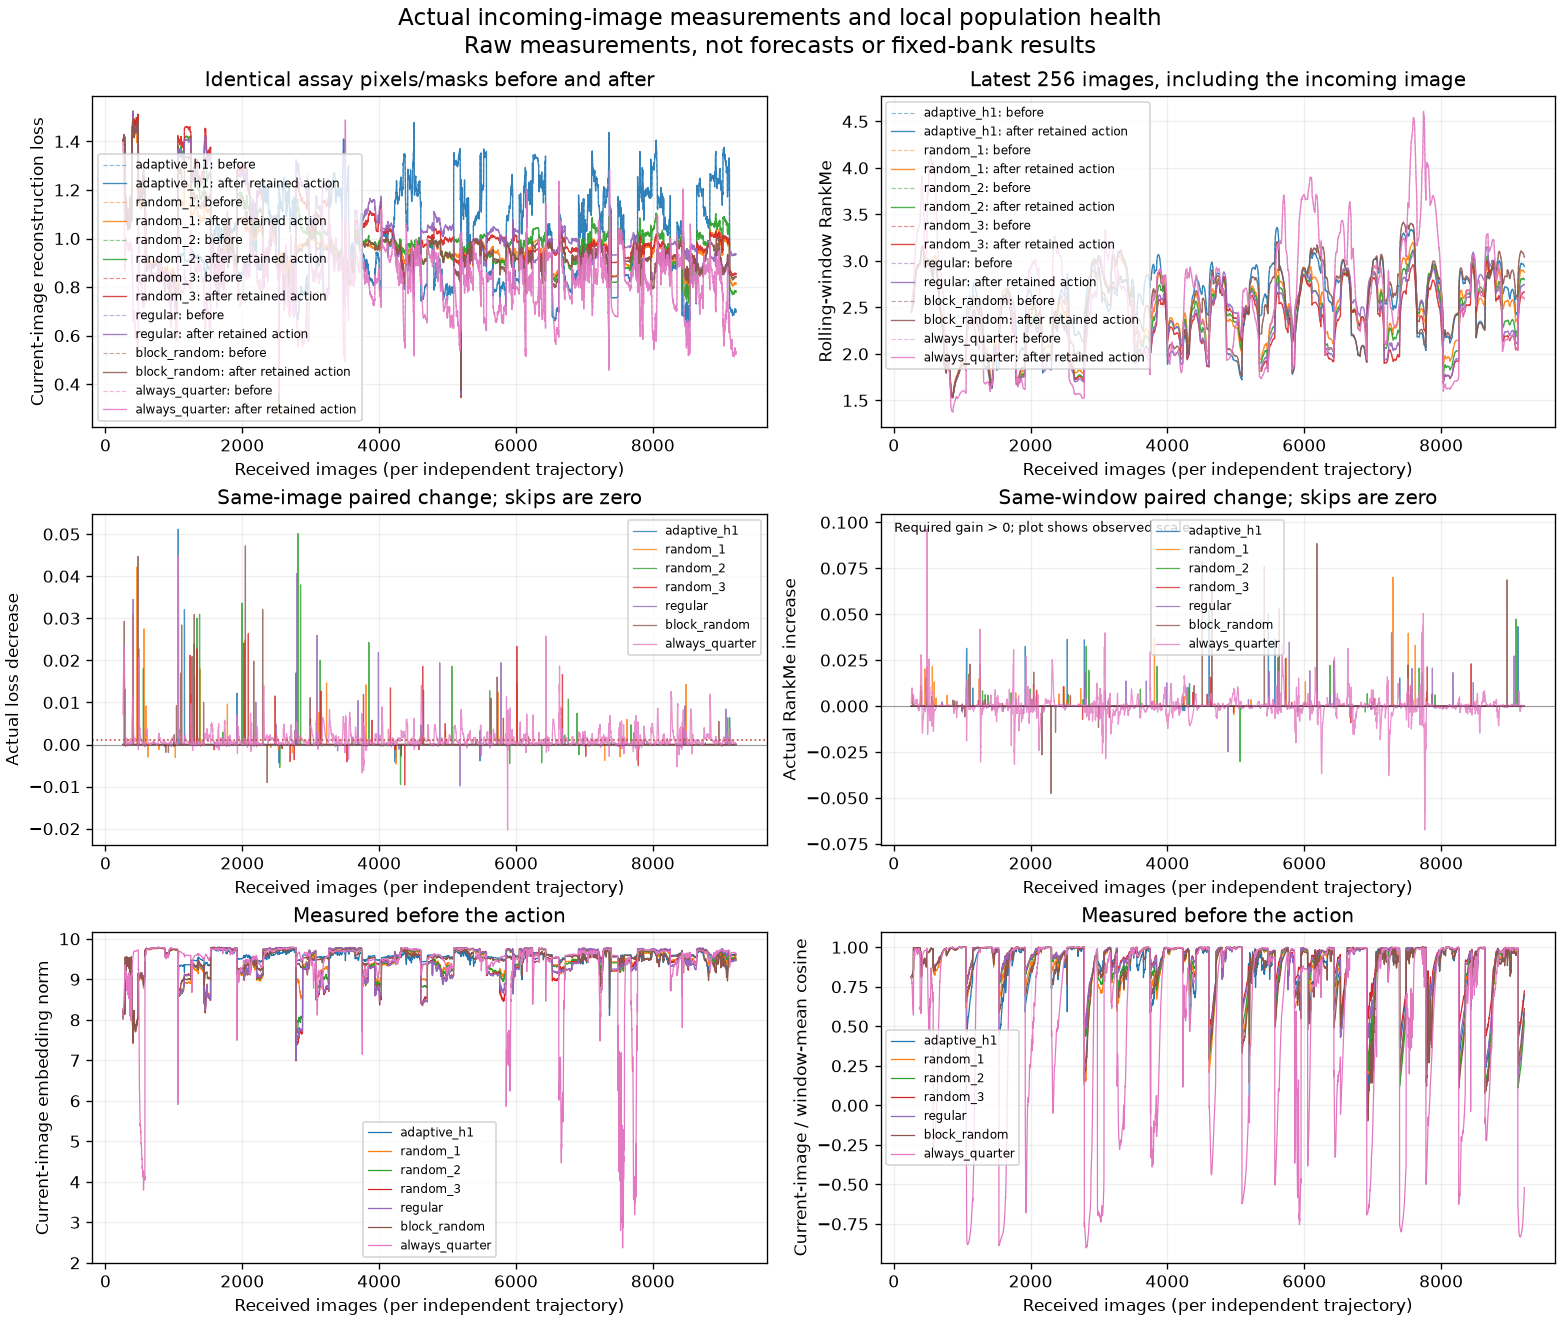

In [2]:
from IPython.display import Image, display
display(Image(filename=str(root / 'families/stream_a/current-image-health.png')))


### stream_a: health


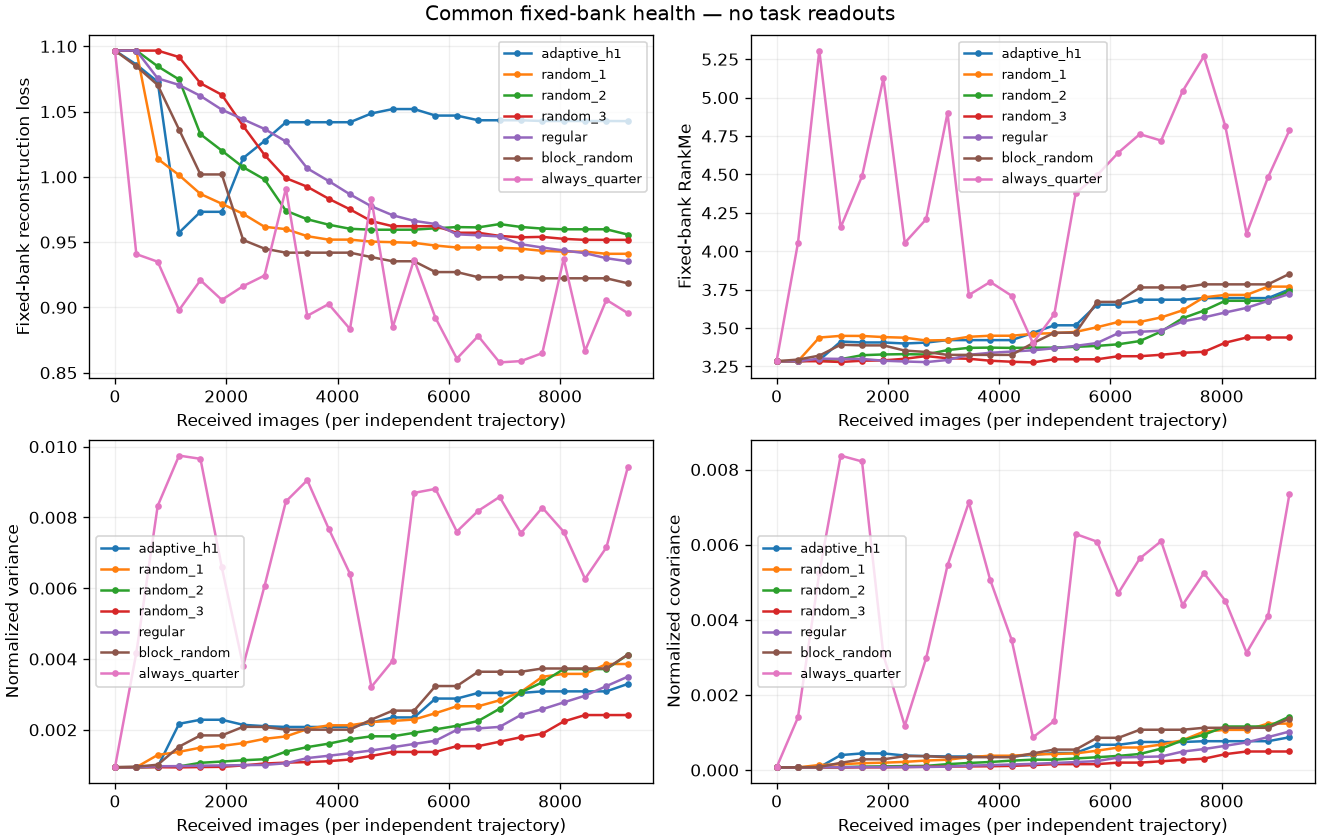

In [3]:
from IPython.display import Image, display
display(Image(filename=str(root / 'families/stream_a/health.png')))


### stream_a: budgets


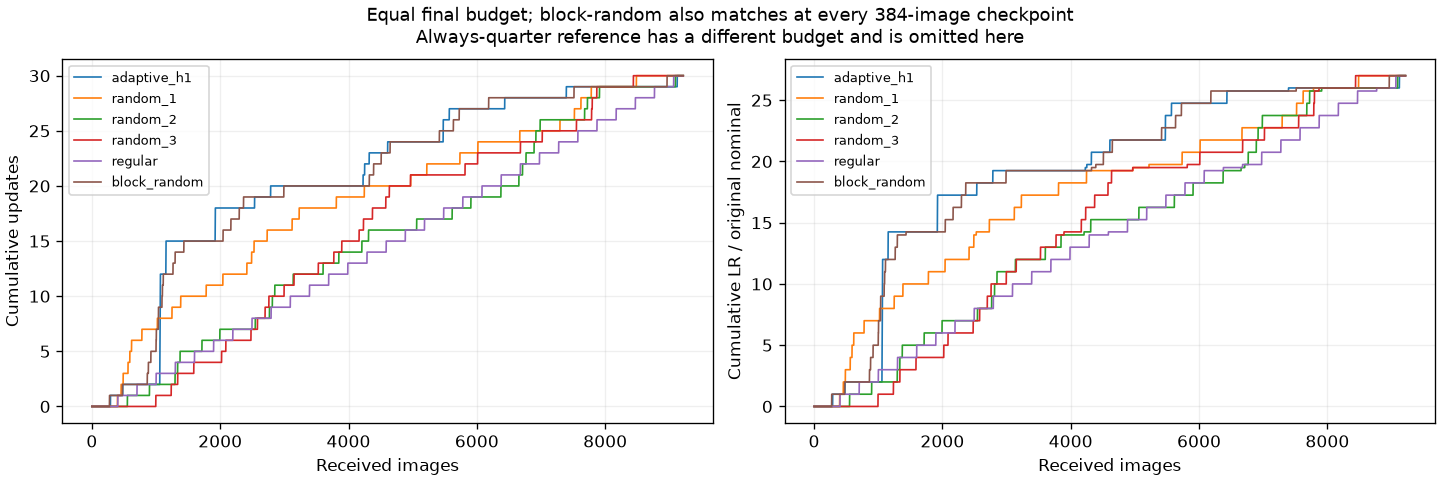

In [4]:
from IPython.display import Image, display
display(Image(filename=str(root / 'families/stream_a/budgets.png')))


### stream_b: current-image-health


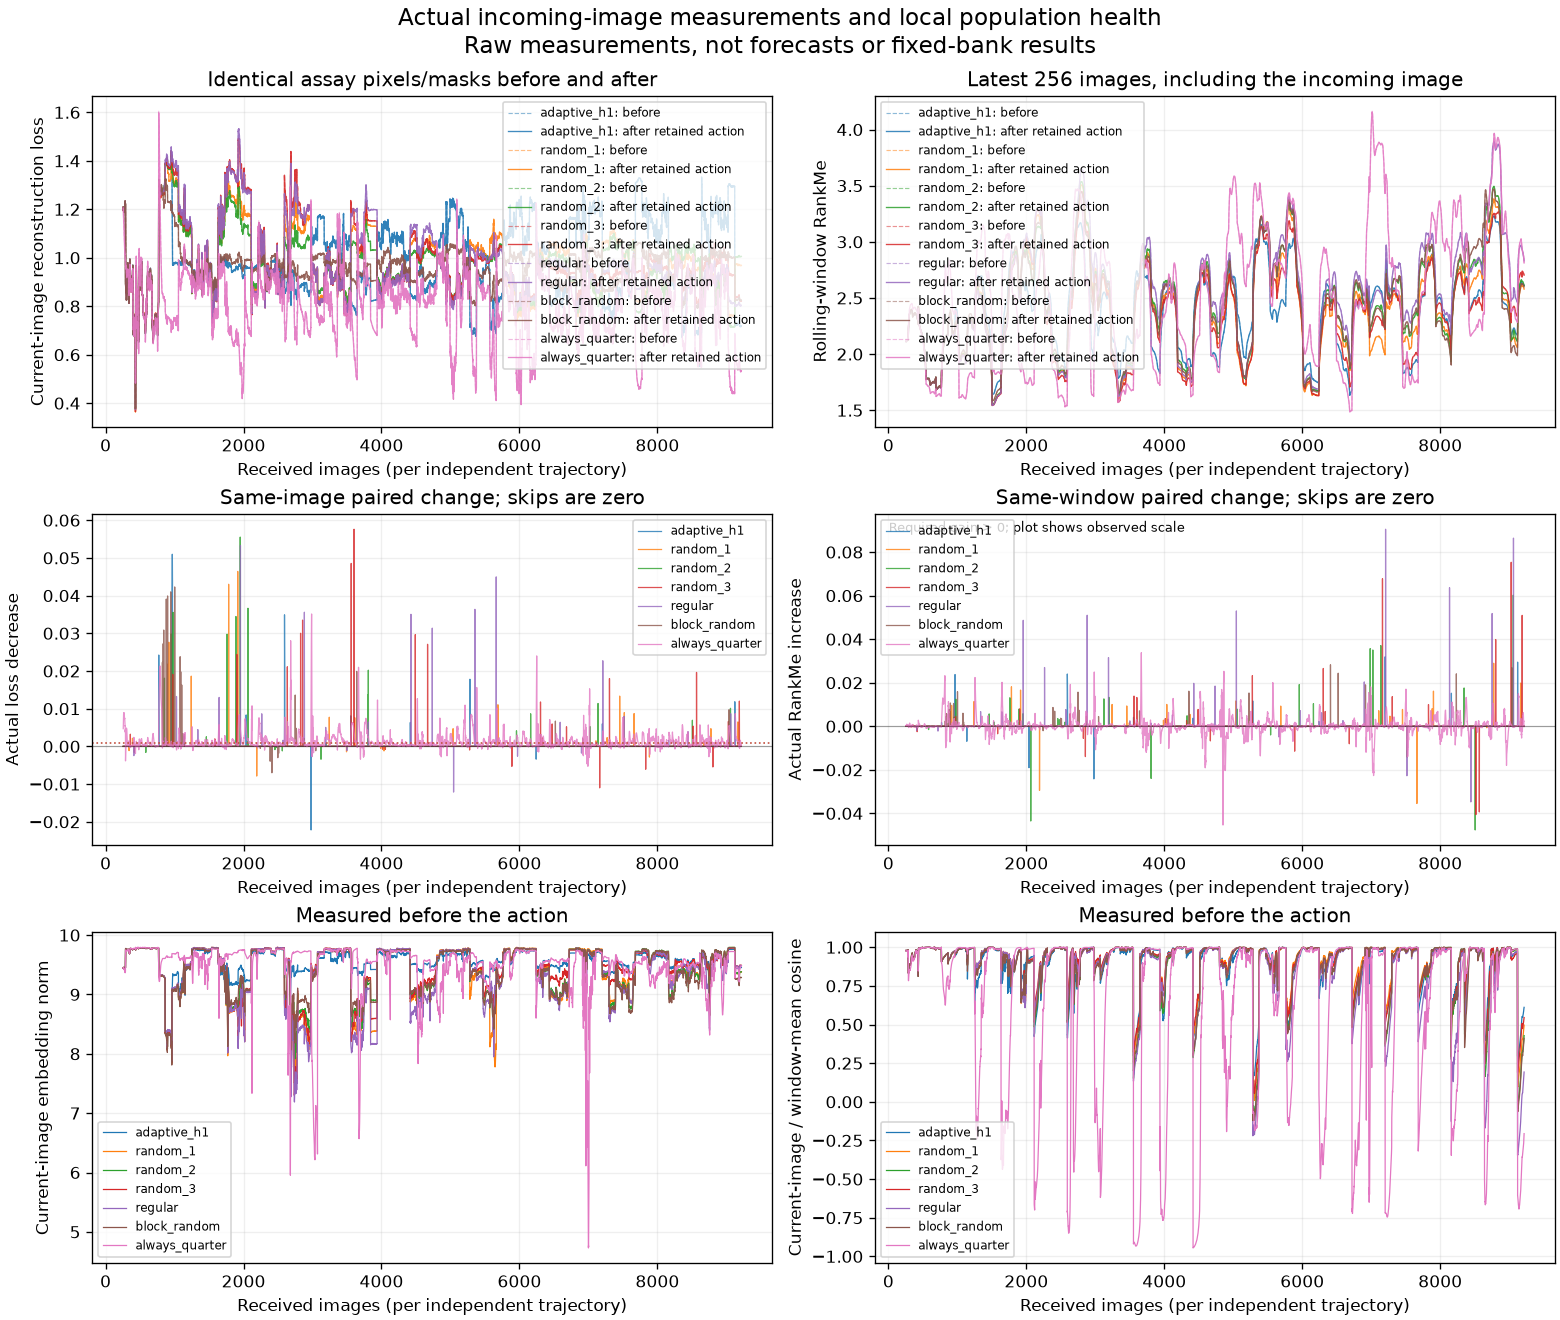

In [5]:
from IPython.display import Image, display
display(Image(filename=str(root / 'families/stream_b/current-image-health.png')))


### stream_b: health


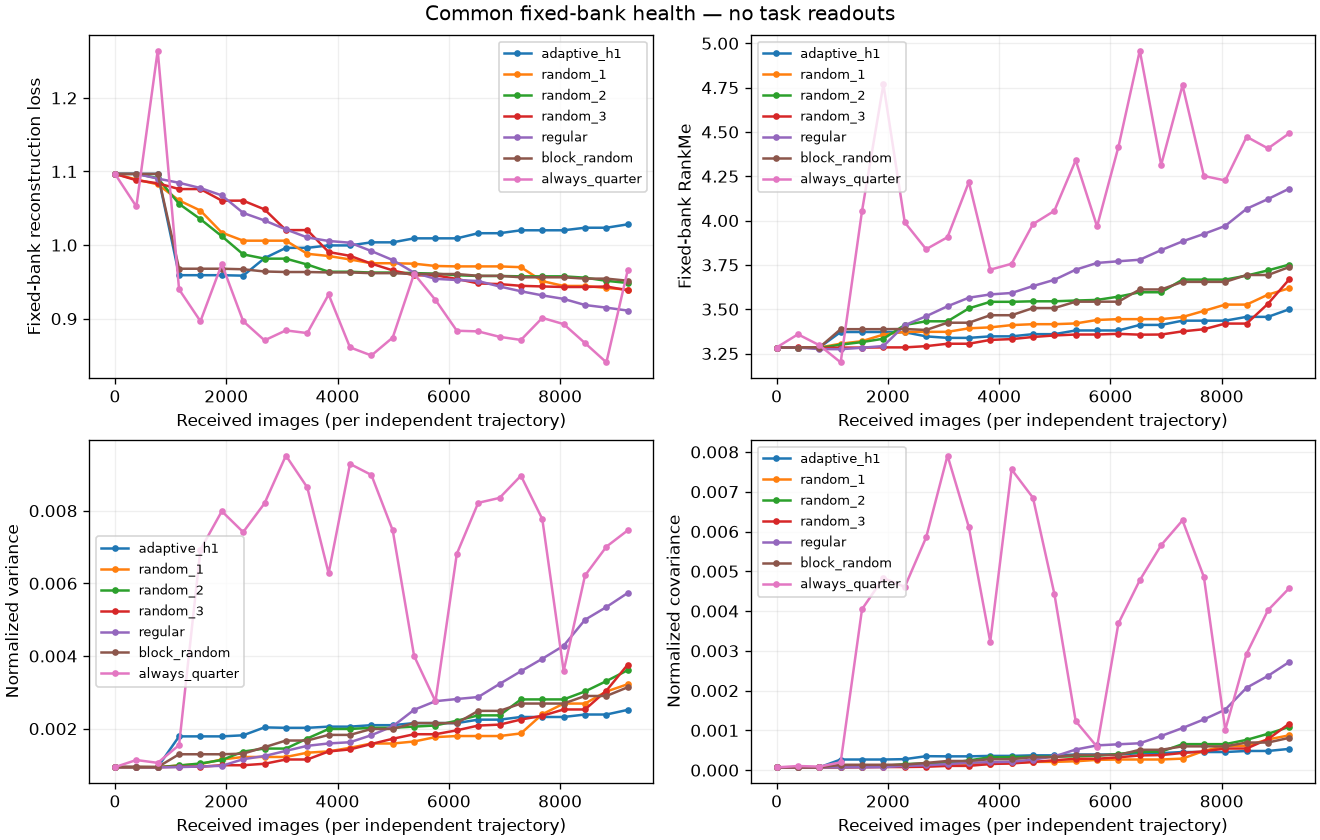

In [6]:
from IPython.display import Image, display
display(Image(filename=str(root / 'families/stream_b/health.png')))


### stream_b: budgets


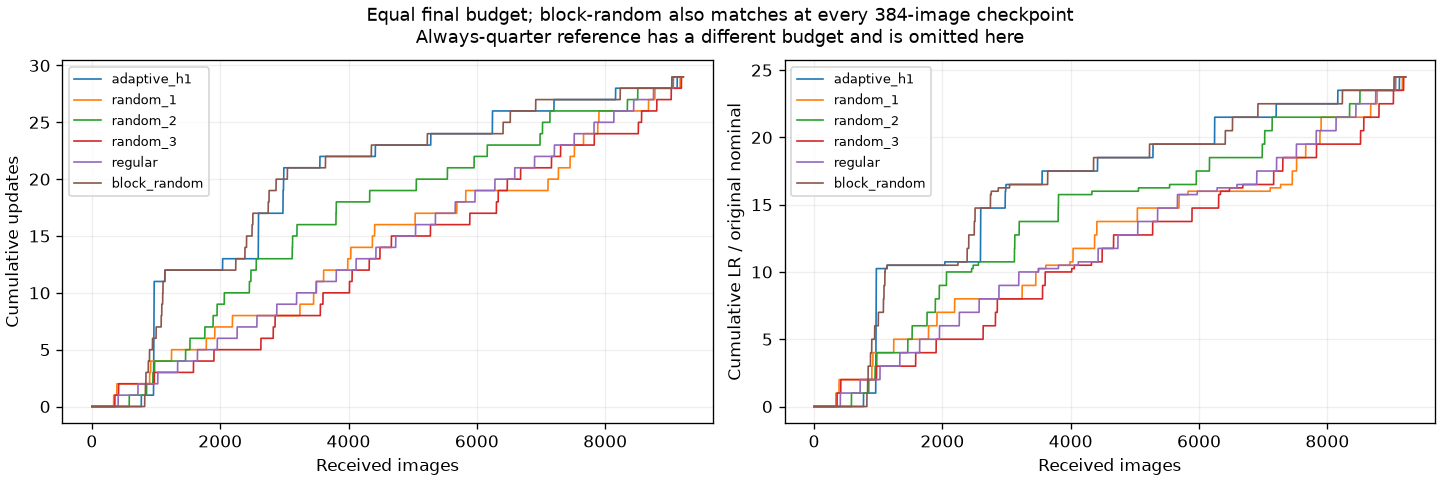

In [7]:
from IPython.display import Image, display
display(Image(filename=str(root / 'families/stream_b/budgets.png')))


### stream_c: current-image-health


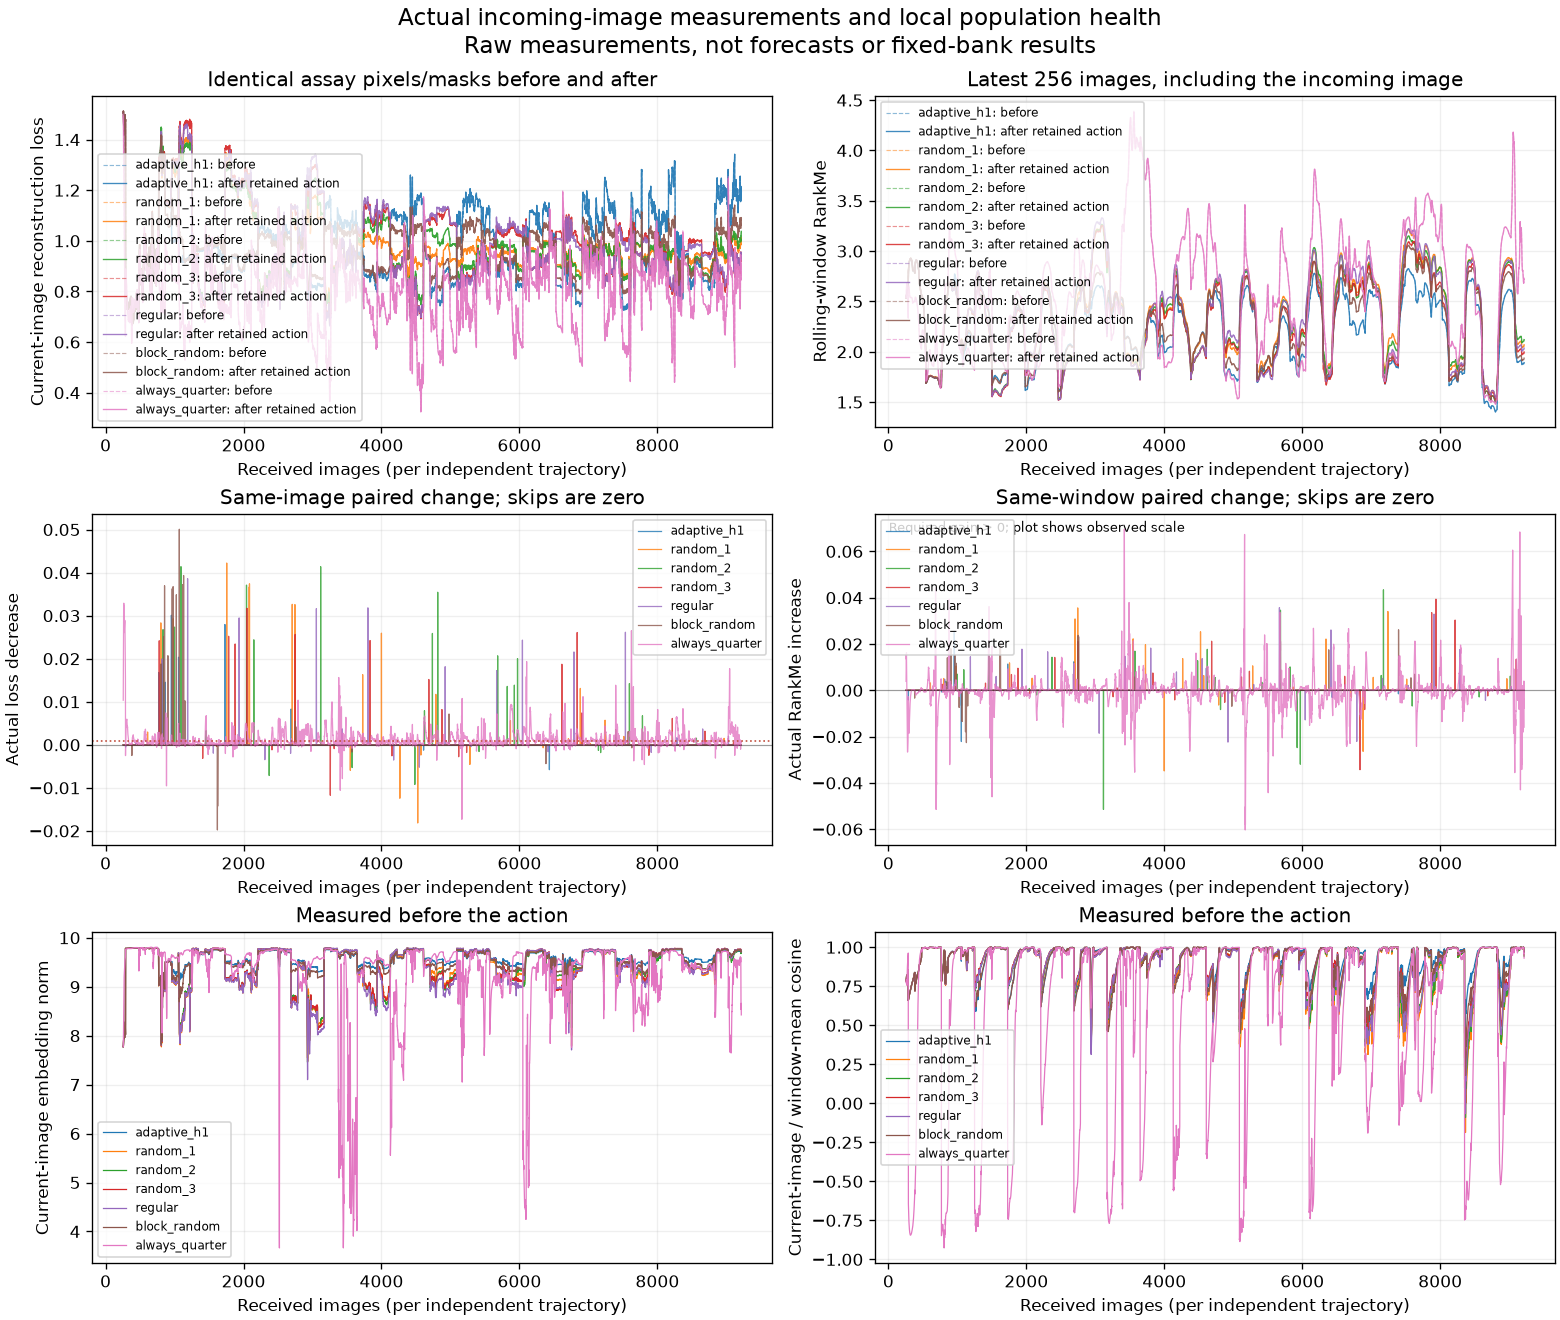

In [8]:
from IPython.display import Image, display
display(Image(filename=str(root / 'families/stream_c/current-image-health.png')))


### stream_c: health


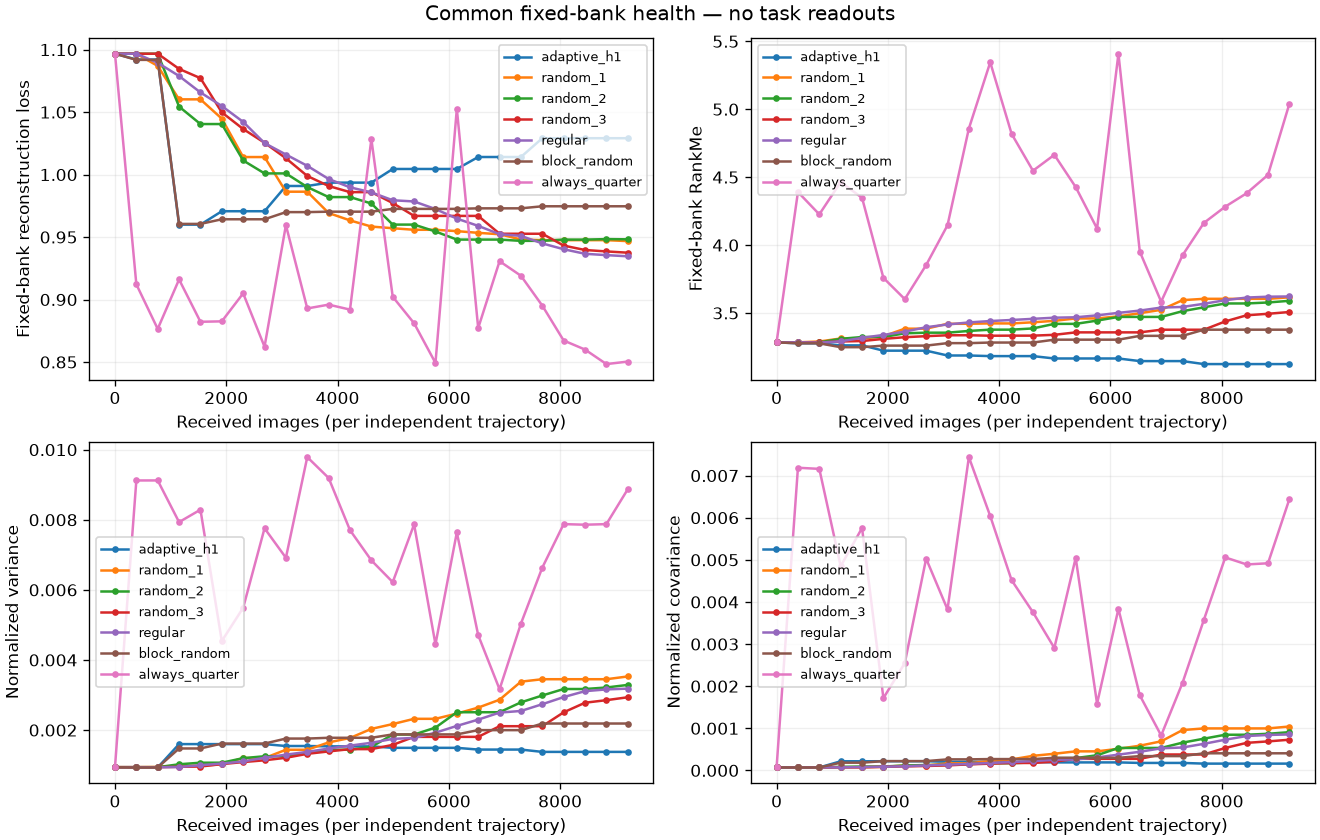

In [9]:
from IPython.display import Image, display
display(Image(filename=str(root / 'families/stream_c/health.png')))


### stream_c: budgets


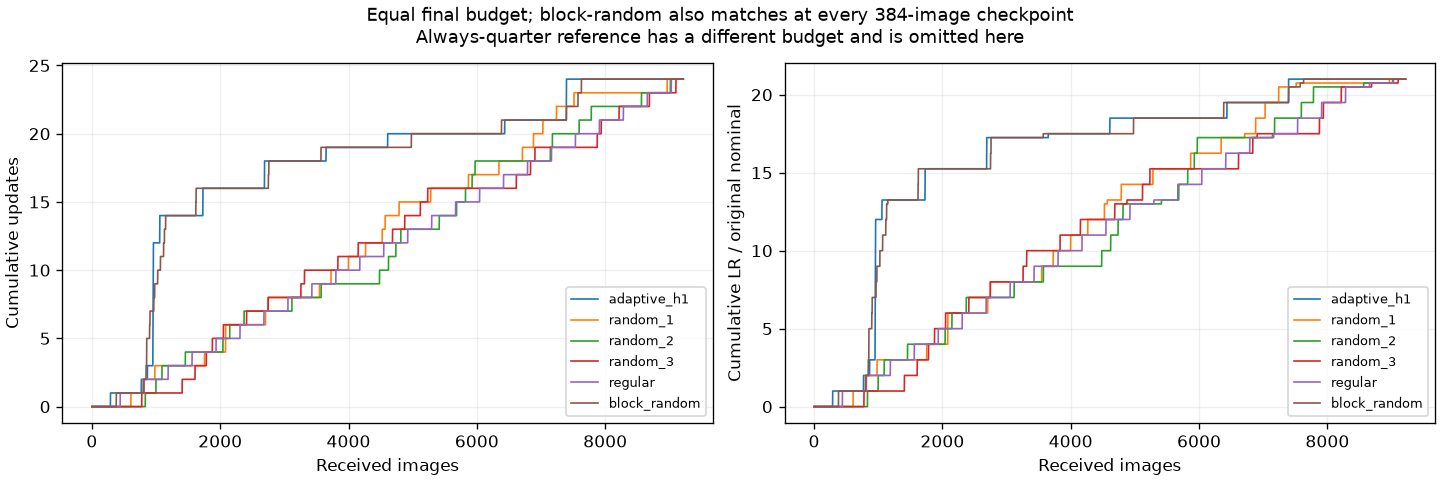

In [10]:
from IPython.display import Image, display
display(Image(filename=str(root / 'families/stream_c/budgets.png')))
